# Sanskrit ↔ English Retrieval: fine-tuning a multilingual embedding model

**Assignment:** AI/ML Model Training, *Option 2 – Train/Fine-Tune a Multilingual Embedding Model for Sanskrit + English Retrieval*

This single notebook runs the **whole project from start to finish**: download data → clean it → measure tokenizers → test baselines → fine-tune → evaluate → analyse errors → RAG demo.
Everything is in this file; nothing else has to be imported.

### What problem are we solving?
A user types an English question (or a Sanskrit verse, even romanised) and the system should return the **matching Sanskrit verse** (and/or its English explanation).
Keyword search cannot do this because Sanskrit (Devanagari) and English share no words. So we use an **embedding model**, which turns every text into a list of numbers so that texts with the same meaning end up *close together*, whatever the language.

### How to use this notebook
1. Open the folder that contains this notebook in VS Code / Jupyter (the notebook must be started **from its own folder**).
2. Choose a kernel with a Python that has `torch` installed. A GPU is recommended; a CPU works with `QUICK_MODE = True`.
3. Run **Kernel → Restart & Run All**. A full run takes about **20 minutes** on a 4 GB laptop GPU (plus a few minutes for the one-time downloads).
4. Results are written to `results/`, trained models to `models/`, data to `data/`.

### Contents
| Part | What happens |
|---|---|
| 0 | Setup and settings |
| 1 | Helper functions (text cleaning, embeddings, metrics) |
| 2 | Download data |
| 3 | Prepare data: training pairs and evaluation tasks |
| 4 | Tokenizer analysis |
| 5 | Baselines (before fine-tuning) |
| 6 | Fine-tuning, run A: in-batch negatives |
| 7 | Hard-negative mining and fine-tuning, run B |
| 8 | Final evaluation and results |
| 9 | Error analysis and before/after examples |
| 10 | Embedding-space analysis |
| 11 | RAG demo |
| 12 | Summary |

## Part 0 — Setup and settings

**Packages.** The next cell installs what is missing (it does nothing if everything is already installed).
`torch` itself is *not* installed here because the right build depends on your machine (CUDA or CPU).

In [1]:
# Run once. Safe to run again.
%pip install -q sentence-transformers "transformers>=4.41" accelerate datasets huggingface_hub rank_bm25 indic-transliteration scikit-learn matplotlib pandas requests ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import json
import random
import re
import time
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

### Settings
Only change things here. The defaults reproduce the results in `REPORT.md`.

In [3]:
# ---------------------------------------------------------------- settings you may change
QUICK_MODE = False            # True = tiny smoke test (a few minutes, numbers are NOT meaningful)
RETRAIN_IF_EXISTS = False     # False = reuse models already saved in models/ (saves time on a re-run)
RUN_LLM_ANSWER = True         # RAG demo: also let a small LLM write an answer (downloads ~1 GB once)

BASE_MODEL_NAME = "intfloat/multilingual-e5-small"   # the model we fine-tune
LLM_NAME = "Qwen/Qwen2.5-0.5B-Instruct"              # only used for the optional RAG answer
RANDOM_SEED = 42

N_ITIHASA_TRAIN = 2_000 if QUICK_MODE else 30_000    # Itihasa pairs added to the Gita pairs
N_ITIHASA_TEST = 200 if QUICK_MODE else 1_000        # size of the Itihasa test benchmark (T5)
GITA_ROUNDS = 3                                      # how many random views we create per Gita verse
EPOCHS = 1
BATCH_SIZE = 16 if QUICK_MODE else 64
MAX_SEQ_LEN = 128                                    # tokens; covers 98% or more of our texts (see Part 4)
LEARNING_RATE = 2e-5
MAX_TRAIN_ROWS = 512 if QUICK_MODE else 0            # 0 = use all rows
TOP_K = 10                                           # we rank the top 10 documents per query

# ---------------------------------------------------------------- folders (all next to this notebook)
ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
CONCEPT_QUERIES_FILE = ROOT / "data" / "concept_queries.json"
for folder in (RAW_DIR, PROCESSED_DIR, MODELS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
assert CONCEPT_QUERIES_FILE.exists(), (
    f"{CONCEPT_QUERIES_FILE} not found. Start Jupyter/VS Code from the folder that contains this notebook "
    "and data/concept_queries.json.")

# ---------------------------------------------------------------- hardware
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
    USE_BF16 = torch.cuda.is_bf16_supported()      # newer GPUs; older ones (e.g. T4) use fp16 instead
    # With less than 10 GB we use "GradCache": same maths, but the batch is processed in small chunks.
    USE_CHUNKED_LOSS = GPU_MEMORY_GB < 10
else:
    GPU_NAME, GPU_MEMORY_GB, USE_BF16, USE_CHUNKED_LOSS = "cpu", 0.0, False, False

print(f"device: {DEVICE} ({GPU_NAME}, {GPU_MEMORY_GB:.1f} GB) | bf16={USE_BF16} | chunked loss={USE_CHUNKED_LOSS}")
print(f"quick mode: {QUICK_MODE} | project folder: {ROOT}")

device: cuda (NVIDIA GeForce RTX 3050 Laptop GPU, 4.3 GB) | bf16=True | chunked loss=True
quick mode: False | project folder: d:\Sanskrit_Assignment2\Submission_Notebook


## Part 1 — Helper functions

Small building blocks used later. Read them once; they are short.

* **Text cleaning** – Sanskrit text from the web contains verse numbers (`।।2.47।।`), invisible characters and different encodings of the *same* letter. We normalise them so that identical text is really identical.
* **Embedding** – turns texts into unit-length vectors. For unit vectors a *dot product equals cosine similarity*.
* **Metrics** – Recall@k, MRR@10 and nDCG@10 (explained where they are used in Part 5).

In [4]:
# ----------------------------------------------------------------------------- reading / writing files
def read_json(path):
    with open(path, encoding="utf-8") as file:
        return json.load(file)


def write_json(data, path):
    with open(path, "w", encoding="utf-8") as file:
        json.dump(data, file, ensure_ascii=False, indent=2)


def read_jsonl(path):
    with open(path, encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


def write_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as file:
        for row in rows:
            file.write(json.dumps(row, ensure_ascii=False) + "\n")


def set_random_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------- text cleaning
# Invisible characters. We keep ZWJ/ZWNJ (‍ ‌): they change how Devanagari conjuncts look.
INVISIBLE_CHARACTERS = dict.fromkeys(map(ord, "​﻿­"), None)
# verse numbers such as  ।।1.1।।  or  ॥ 2.47 ॥
VERSE_NUMBER_MARKER = re.compile(r"[।॥|]{1,2}\s*[\d०-९]+(\s*[.\-]\s*[\d०-९]+)*\s*[।॥|]{1,2}")
# a verse number at the start of an English translation, e.g. "2.47 Your right is ..."
LEADING_VERSE_NUMBER = re.compile(r"^\s*(\d+\s*[.:]\s*\d+(\s*[-–]\s*\d+)?|\d+)\s*[.:)\-–]?\s+")


def normalize_unicode_text(text):
    """NFC-normalise, drop invisible characters, collapse whitespace."""
    if not text:
        return ""
    text = unicodedata.normalize("NFC", text).translate(INVISIBLE_CHARACTERS)
    return re.sub(r"\s+", " ", text).strip()


def clean_sanskrit_verse(text):
    """Replace '।।1.1।।' style numbering by a single '॥' and tidy the spaces."""
    text = unicodedata.normalize("NFC", text or "")
    text = VERSE_NUMBER_MARKER.sub(" ॥ ", text)
    text = normalize_unicode_text(text)
    return re.sub(r"(\s*॥\s*)+$", " ॥", text).strip()


def clean_english_translation(text):
    return LEADING_VERSE_NUMBER.sub("", normalize_unicode_text(text)).strip()


def remove_diacritics(text):
    """'karmaṇy evādhikāras' -> 'karmany evadhikaras' (how people type without special keys)."""
    decomposed = unicodedata.normalize("NFD", text)
    return "".join(ch for ch in decomposed if not unicodedata.combining(ch)).lower()


# ----------------------------------------------------------------------------- embeddings
def get_query_and_passage_prefixes(model_name):
    """e5 models were trained with 'query: ' / 'passage: ' in front of the text; bge uses an instruction."""
    name = str(model_name).lower()
    if "bge" in name:
        return "Represent this sentence for searching relevant passages: ", ""
    return "query: ", "passage: "


def embed_texts(model, texts, role, model_name, batch_size=64, show_progress=False):
    """role = 'query' or 'passage'. Returns unit-length vectors (dot product == cosine similarity)."""
    query_prefix, passage_prefix = get_query_and_passage_prefixes(model_name)
    prefix = query_prefix if role == "query" else passage_prefix
    vectors = model.encode([prefix + text for text in texts], batch_size=batch_size, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=show_progress)
    return vectors.astype(np.float32)


# ----------------------------------------------------------------------------- metrics
def top_k_indices(score_matrix, k):
    """For every query (row): indices of its k best-scoring documents, best first."""
    k = min(k, score_matrix.shape[1])
    unsorted_top = np.argpartition(-score_matrix, kth=k - 1, axis=1)[:, :k]
    scores_of_top = np.take_along_axis(score_matrix, unsorted_top, axis=1)
    best_first = scores_of_top.argsort(axis=1)[:, ::-1]
    return np.take_along_axis(unsorted_top, best_first, axis=1)


def compute_retrieval_metrics(ranked_doc_indices, relevant_doc_sets, recall_cutoffs=(1, 5, 10)):
    """Recall@k, MRR@10, nDCG@10 with binary relevance.

    Returns (metrics, first_hit_ranks, reciprocal_ranks); first_hit_ranks is 1-based, 0 = not in the list.
    """
    recall_per_query = {k: [] for k in recall_cutoffs}
    reciprocal_ranks, ndcg_scores, first_hit_ranks = [], [], []
    for ranked_docs, relevant_docs in zip(ranked_doc_indices, relevant_doc_sets):
        is_hit = [1 if doc in relevant_docs else 0 for doc in ranked_docs]
        for k in recall_cutoffs:
            recall_per_query[k].append(sum(is_hit[:k]) / len(relevant_docs))
        first_hit = next((position + 1 for position, hit in enumerate(is_hit) if hit), 0)
        first_hit_ranks.append(first_hit)
        reciprocal_ranks.append(1.0 / first_hit if 0 < first_hit <= 10 else 0.0)
        dcg = sum(hit / np.log2(position + 2) for position, hit in enumerate(is_hit[:10]))
        ideal_dcg = sum(1 / np.log2(position + 2) for position in range(min(len(relevant_docs), 10)))
        ndcg_scores.append(dcg / ideal_dcg)
    metrics = {f"R@{k}": float(np.mean(v)) for k, v in recall_per_query.items()}
    metrics["MRR@10"] = float(np.mean(reciprocal_ranks))
    metrics["nDCG@10"] = float(np.mean(ndcg_scores))
    metrics["n_queries"] = len(relevant_doc_sets)
    return metrics, first_hit_ranks, reciprocal_ranks


def bootstrap_confidence_interval(values, n_resamples=1000, seed=RANDOM_SEED):
    """95% confidence interval of a mean (resampling queries with replacement)."""
    values = np.asarray(values, dtype=np.float64)
    resampled_means = np.random.default_rng(seed).choice(values, size=(n_resamples, len(values)), replace=True).mean(axis=1)
    return float(np.percentile(resampled_means, 2.5)), float(np.percentile(resampled_means, 97.5))


def dataframe_to_markdown(df, float_format="{:.3f}"):
    """Tiny markdown-table writer (so we do not need extra packages)."""
    header = "| " + " | ".join([df.index.name or ""] + [str(c) for c in df.columns]) + " |"
    line = "|" + "---|" * (len(df.columns) + 1)
    rows = ["| " + " | ".join([str(i)] + [float_format.format(v) if isinstance(v, float) else str(v) for v in r]) + " |"
            for i, r in zip(df.index, df.values)]
    return "\n".join([header, line] + rows)


set_random_seed()
print("helpers ready")

helpers ready


## Part 2 — Download the data

| Source | What it gives us |
|---|---|
| **Bhagavad Gita** (`github.com/gita/gita`) | 701 verses: Devanagari text, a romanisation, word-by-word meanings, and several English translations |
| **Itihasa** (`rahular/itihasa` on Hugging Face) | ~93,000 Sanskrit–English verse pairs from the Ramayana and the Mahabharata |

> *Why not `load_dataset("rahular/itihasa")`?* That dataset uses a loading **script**, which current versions of the `datasets` library refuse to run. So we download the raw files directly. They are named `.csv` but are plain text, one verse per line.

In [5]:
import shutil
import requests

GITA_BASE_URL = "https://raw.githubusercontent.com/gita/gita/main/data/"
GITA_FILES = ["verse.json", "translation.json", "chapters.json"]
ITIHASA_FILES = [f"{split}.{lang}.csv" for split in ("train", "dev", "test") for lang in ("sn", "en")]


def file_exists(path):
    return path.exists() and path.stat().st_size > 0


(RAW_DIR / "gita").mkdir(parents=True, exist_ok=True)
for file_name in GITA_FILES:
    destination = RAW_DIR / "gita" / file_name
    if file_exists(destination):
        continue
    print("downloading", GITA_BASE_URL + file_name)
    response = requests.get(GITA_BASE_URL + file_name, timeout=120)
    response.raise_for_status()
    destination.write_bytes(response.content)

from huggingface_hub import hf_hub_download

(RAW_DIR / "itihasa").mkdir(parents=True, exist_ok=True)
for file_name in ITIHASA_FILES:
    destination = RAW_DIR / "itihasa" / file_name
    if file_exists(destination):
        continue
    print("downloading itihasa", file_name)
    shutil.copyfile(hf_hub_download(repo_id="rahular/itihasa", repo_type="dataset", filename=file_name), destination)

for path in sorted(RAW_DIR.rglob("*")):
    if path.is_file():
        print(f"{str(path.relative_to(RAW_DIR)):28s} {path.stat().st_size / 1e6:6.1f} MB")

gita\chapters.json              0.0 MB
gita\translation.json           2.3 MB
gita\verse.json                 0.7 MB
itihasa\dev.en.csv              1.1 MB
itihasa\dev.sn.csv              1.7 MB
itihasa\test.en.csv             2.1 MB
itihasa\test.sn.csv             3.2 MB
itihasa\train.en.csv           13.5 MB
itihasa\train.sn.csv           20.6 MB


## Part 3 — Prepare the data

### 3.1 One clean record per Gita verse
We merge `verse.json` and `translation.json`. For each verse we keep:
the Devanagari text, four romanisations (the dataset's own, IAST, ITRANS, plain ASCII), the English word-by-word glosses and the English translations of five translators.

In [6]:
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate


def load_gita_verses():
    raw_verses = read_json(RAW_DIR / "gita" / "verse.json")
    raw_translations = read_json(RAW_DIR / "gita" / "translation.json")

    verses_by_id = {}
    for raw in raw_verses:
        sanskrit = clean_sanskrit_verse(raw["text"])

        # "word_meanings" looks like "dharma-kṣhetre—the land of dharma; kuru-kṣhetre—at Kurukshetra; ..."
        english_word_glosses = []
        for entry in (raw.get("word_meanings") or "").split(";"):
            if "—" in entry:
                gloss = normalize_unicode_text(entry.split("—", 1)[1])
                if gloss:
                    english_word_glosses.append(gloss)

        iast = transliterate(sanskrit, sanscript.DEVANAGARI, sanscript.IAST)
        verses_by_id[raw["id"]] = {
            "verse_id": raw["id"],
            "verse_ref": f'{raw["chapter_number"]}.{raw["verse_number"]}',      # e.g. "2.47"
            "sanskrit": sanskrit,
            "romanized_dataset_style": normalize_unicode_text(raw.get("transliteration", "")),
            "romanized_iast": iast,
            "romanized_itrans": transliterate(sanskrit, sanscript.DEVANAGARI, sanscript.ITRANS),
            "romanized_harvard_kyoto": transliterate(sanskrit, sanscript.DEVANAGARI, sanscript.HK),
            "romanized_ascii": remove_diacritics(iast),                         # no special characters
            "english_word_glosses": english_word_glosses,
            "english_by_author": {},
        }

    for translation in raw_translations:
        if translation.get("lang") != "english" or translation.get("verse_id") not in verses_by_id:
            continue
        text = clean_english_translation(translation.get("description", ""))
        if len(text) >= 10:
            verses_by_id[translation["verse_id"]]["english_by_author"][translation["authorName"]] = text
    return [verses_by_id[verse_id] for verse_id in sorted(verses_by_id)]


verses = load_gita_verses()
print(f"{len(verses)} verses loaded")
display(pd.DataFrame([{
    "ref": v["verse_ref"], "Devanagari": v["sanskrit"], "IAST": v["romanized_iast"], "plain ASCII": v["romanized_ascii"],
    "English (Sivananda)": v["english_by_author"]["Swami Sivananda"][:110],
} for v in (verses[0], verses[46], verses[100])]))

701 verses loaded


,ref,Devanagari,IAST,plain ASCII,English (Sivananda)
0,1.1,धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर...,dhṛtarāṣṭra uvāca dharmakṣetre kurukṣetre samavetā yuyutsavaḥ| māmakāḥ pāṇḍavāścaiva k...,dhrtarastra uvaca dharmaksetre kuruksetre samaveta yuyutsavah| mamakah pandavascaiva k...,"Dhritarashtra said, ""What did my people and the sons of Pandu do when they had assembl..."
1,1.47,सञ्जय उवाच एवमुक्त्वाऽर्जुनः संख्ये रथोपस्थ उपाविशत्। विसृज्य सशरं चापं शोकसंविग्नमानसः ॥,sañjaya uvāca evamuktvā'rjunaḥ saṃkhye rathopastha upāviśat| visṛjya saśaraṃ cāpaṃ śok...,sanjaya uvaca evamuktva'rjunah samkhye rathopastha upavisat| visrjya sasaram capam sok...,"Sanjaya said, Having thus spoken in the midst of the battlefield, Arjuna cast away his..."
2,2.54,अर्जुन उवाच स्थितप्रज्ञस्य का भाषा समाधिस्थस्य केशव। स्थितधीः किं प्रभाषेत किमासीत व्र...,arjuna uvāca sthitaprajñasya kā bhāṣā samādhisthasya keśava| sthitadhīḥ kiṃ prabhāṣeta...,arjuna uvaca sthitaprajnasya ka bhasa samadhisthasya kesava| sthitadhih kim prabhaseta...,"Arjuna said, ""O Krishna, what is the description of one who has steady wisdom and is m..."


In [7]:
verses[0]

{'verse_id': 1,
 'verse_ref': '1.1',
 'sanskrit': 'धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥',
 'romanized_dataset_style': 'dhṛitarāśhtra uvācha dharma-kṣhetre kuru-kṣhetre samavetā yuyutsavaḥ māmakāḥ pāṇḍavāśhchaiva kimakurvata sañjaya',
 'romanized_iast': 'dhṛtarāṣṭra uvāca dharmakṣetre kurukṣetre samavetā yuyutsavaḥ| māmakāḥ pāṇḍavāścaiva kimakurvata sañjaya ||',
 'romanized_itrans': 'dhRRitarAShTra uvAcha dharmakShetre kurukShetre samavetA yuyutsavaH| mAmakAH pANDavAshchaiva kimakurvata sa~njaya ||',
 'romanized_harvard_kyoto': 'dhRtarASTra uvAca dharmakSetre kurukSetre samavetA yuyutsavaH| mAmakAH pANDavAzcaiva kimakurvata saJjaya ||',
 'romanized_ascii': 'dhrtarastra uvaca dharmaksetre kuruksetre samaveta yuyutsavah| mamakah pandavascaiva kimakurvata sanjaya ||',
 'english_word_glosses': ['Dhritarashtra said',
  'the land of dharma',
  'at Kurukshetra',
  'having gathered',
  'desiring to fight',
  'my sons',
  'the sons of 

### 3.2 Who translates what? (avoiding leakage)
We have five English translators. To get an honest test:

* **Shri Purohit Swami** (a free, paraphrasing translation) is *never* used for training. His text becomes the test queries, so the model is tested on wording it has never seen.
* **Swami Sivananda** is the English side of the searchable corpus for Sanskrit → English search.
* The other four translators are used to build training pairs.

In [8]:
HELD_OUT_QUERY_AUTHOR = "Shri Purohit Swami"
ENGLISH_CORPUS_AUTHOR = "Swami Sivananda"
    
verses_per_author = Counter(author for verse in verses for author in verse["english_by_author"])
print("verses covered per translator:", dict(verses_per_author))
well_covered = [a for a, n in verses_per_author.most_common() if n >= 0.9 * len(verses)]
assert HELD_OUT_QUERY_AUTHOR in well_covered and ENGLISH_CORPUS_AUTHOR in well_covered

TRAINING_AUTHORS = [a for a in well_covered if a != HELD_OUT_QUERY_AUTHOR]
print("training translators:", TRAINING_AUTHORS)

verses covered per translator: {'Swami Adidevananda': 701, 'Swami Gambirananda': 701, 'Swami Sivananda': 701, 'Dr. S. Sankaranarayan': 701, 'Shri Purohit Swami': 701}
training translators: ['Swami Adidevananda', 'Swami Gambirananda', 'Swami Sivananda', 'Dr. S. Sankaranarayan']


### 3.3 Split verses into train / validation / test
* 75% train, 5% validation, 20% test.
* The 30 hand-written questions in `data/concept_queries.json` point to specific verses (e.g. *"acting without attachment to results"* → 2.47). Those verses are **forced into the test set**, so they can never leak into training.

In [32]:
concept_questions = read_json(CONCEPT_QUERIES_FILE)
concept_verse_refs = {ref for question in concept_questions for ref in question["relevant"]}
known_refs = {verse["verse_ref"] for verse in verses}
unknown = sorted(concept_verse_refs - known_refs)
assert not unknown, f"concept_queries.json mentions verses that do not exist: {unknown}"


def assign_train_val_test_split(verses, test_fraction=0.20, val_fraction=0.05):
    """Adds verse['split']. Verses with identical Devanagari text always share a split."""
    groups_by_text = defaultdict(list)
    for verse in verses:
        groups_by_text[verse["sanskrit"]].append(verse)
    groups = list(groups_by_text.values())
    random.Random(RANDOM_SEED).shuffle(groups)

    split_of_verse = {}
    for group in groups:                                   # first: verses used by concept questions -> test
        if any(verse["verse_ref"] in concept_verse_refs for verse in group):
            for verse in group:
                split_of_verse[verse["verse_id"]] = "test"
    n_test = sum(1 for s in split_of_verse.values() if s == "test")
    n_val = 0
    for group in groups:
        if group[0]["verse_id"] in split_of_verse:
            continue
        if n_test < test_fraction * len(verses):
            chosen, n_test = "test", n_test + len(group)
        elif n_val < val_fraction * len(verses):
            chosen, n_val = "val", n_val + len(group)
        else:
            chosen = "train"
        for verse in group:
            split_of_verse[verse["verse_id"]] = chosen
    for verse in verses:
        verse["split"] = split_of_verse[verse["verse_id"]]


assign_train_val_test_split(verses)
print("verses per split:", dict(Counter(v["split"] for v in verses)))
write_jsonl(verses, PROCESSED_DIR / "gita_verses.jsonl")

verses per split: {'train': 524, 'test': 141, 'val': 36}


In [35]:
concept_verse_refs

{'1.28',
 '1.29',
 '1.30',
 '10.20',
 '11.12',
 '11.32',
 '14.5',
 '15.1',
 '16.1',
 '16.2',
 '16.21',
 '16.3',
 '17.10',
 '17.8',
 '17.9',
 '18.47',
 '18.61',
 '18.65',
 '18.66',
 '2.13',
 '2.19',
 '2.20',
 '2.22',
 '2.23',
 '2.24',
 '2.38',
 '2.47',
 '2.48',
 '2.50',
 '2.54',
 '2.55',
 '2.56',
 '2.58',
 '2.62',
 '2.63',
 '2.9',
 '3.14',
 '3.19',
 '3.35',
 '3.37',
 '3.39',
 '4.20',
 '4.38',
 '4.7',
 '4.8',
 '6.11',
 '6.12',
 '6.13',
 '6.16',
 '6.17',
 '6.34',
 '6.35',
 '6.5',
 '6.6',
 '8.5',
 '8.6',
 '9.26',
 '9.27',
 '9.34'}

In [10]:
#to see one train data sample
verses[0]

{'verse_id': 1,
 'verse_ref': '1.1',
 'sanskrit': 'धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥',
 'romanized_dataset_style': 'dhṛitarāśhtra uvācha dharma-kṣhetre kuru-kṣhetre samavetā yuyutsavaḥ māmakāḥ pāṇḍavāśhchaiva kimakurvata sañjaya',
 'romanized_iast': 'dhṛtarāṣṭra uvāca dharmakṣetre kurukṣetre samavetā yuyutsavaḥ| māmakāḥ pāṇḍavāścaiva kimakurvata sañjaya ||',
 'romanized_itrans': 'dhRRitarAShTra uvAcha dharmakShetre kurukShetre samavetA yuyutsavaH| mAmakAH pANDavAshchaiva kimakurvata sa~njaya ||',
 'romanized_harvard_kyoto': 'dhRtarASTra uvAca dharmakSetre kurukSetre samavetA yuyutsavaH| mAmakAH pANDavAzcaiva kimakurvata saJjaya ||',
 'romanized_ascii': 'dhrtarastra uvaca dharmaksetre kuruksetre samaveta yuyutsavah| mamakah pandavascaiva kimakurvata sanjaya ||',
 'english_word_glosses': ['Dhritarashtra said',
  'the land of dharma',
  'at Kurukshetra',
  'having gathered',
  'desiring to fight',
  'my sons',
  'the sons of 

### 3.4 Training pairs from the Gita
Contrastive learning needs **(anchor, positive)** pairs: two texts that should be close together. From every *training* verse we create four kinds of pairs, each containing the Devanagari verse:

| # | anchor → positive | teaches the model |
|---|---|---|
| a | English translation → Devanagari verse | English meaning ↔ Sanskrit |
| b | Devanagari verse → English translation | the reverse direction |
| c | romanised verse (random style) → Devanagari verse | spelling/transliteration variants |
| d | keywords from the word-by-word glosses → Devanagari verse | short, keyword-style queries |

Each verse is used `GITA_ROUNDS` times with different random choices (which translator, which romanisation).

In [11]:
ROMANIZATION_STYLES = ["romanized_dataset_style", "romanized_iast", "romanized_itrans",
                       "romanized_harvard_kyoto", "romanized_ascii"]


def build_gita_training_pairs(verses_of_split, rng, rounds):
    pairs = []
    for verse in verses_of_split:
        available_authors = [a for a in TRAINING_AUTHORS if a in verse["english_by_author"]]
        if not available_authors:
            continue
        devanagari = verse["sanskrit"]
        for _ in range(rounds):
            base = {"source": "gita", "verse_id": verse["verse_id"]}
            english = verse["english_by_author"][rng.choice(available_authors)]
            pairs.append({**base, "anchor": english, "positive": devanagari, "positive_language": "sanskrit"})     # (a)
            english = verse["english_by_author"][rng.choice(available_authors)]
            pairs.append({**base, "anchor": devanagari, "positive": english, "positive_language": "english"})      # (b)
            romanized = verse[rng.choice(ROMANIZATION_STYLES)]
            if romanized:
                pairs.append({**base, "anchor": romanized, "positive": devanagari, "positive_language": "sanskrit"})  # (c)
            glosses = verse["english_word_glosses"]
            if len(glosses) >= 3:
                keywords = ", ".join(rng.sample(glosses, min(len(glosses), rng.randint(4, 10))))
                pairs.append({**base, "anchor": keywords, "positive": devanagari, "positive_language": "sanskrit"})  # (d)
    return pairs


rng = random.Random(RANDOM_SEED)
gita_train_pairs = build_gita_training_pairs([v for v in verses if v["split"] == "train"], rng, GITA_ROUNDS)
gita_val_pairs = build_gita_training_pairs([v for v in verses if v["split"] == "val"], rng, 1)
print(f"Gita training pairs: {len(gita_train_pairs)} | validation pairs: {len(gita_val_pairs)}")
display(pd.DataFrame(gita_train_pairs[:4])[["anchor", "positive"]])

Gita training pairs: 6285 | validation pairs: 144


,anchor,positive
0,"Dhṛtarāṣṭra said: “O Sanjaya, what did my people and the Pāṇḍavas do, gathered togethe...",धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर...
1,धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर...,"Dhṛtarāṣṭra said: “O Sanjaya, what did my people and the Pāṇḍavas do, gathered togethe..."
2,dhRRitarAShTra uvAcha dharmakShetre kurukShetre samavetA yuyutsavaH| mAmakAH pANDavAsh...,धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर...
3,"having gathered, at Kurukshetra, the land of dharma, certainly, what",धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर...


### 3.5 Training pairs from Itihasa (and removing Gita overlap)
Itihasa adds ~30,000 more Sanskrit–English pairs from other epics, so the model sees much more Sanskrit.

**Careful:** the Mahabharata *contains* the Bhagavad Gita. If we trained on those lines, our test verses would leak into training. So we drop every Itihasa verse whose character 8-grams overlap the Gita by more than 30%.

In [12]:
def read_itihasa_split(split):
    """Returns (sanskrit, english) pairs. Line i of the .sn file matches line i of the .en file."""
    with open(RAW_DIR / "itihasa" / f"{split}.sn.csv", encoding="utf-8") as file:
        sanskrit_lines = file.read().split("\n")
    with open(RAW_DIR / "itihasa" / f"{split}.en.csv", encoding="utf-8") as file:
        english_lines = file.read().split("\n")
    assert len(sanskrit_lines) == len(english_lines), "Sanskrit and English files have different line counts"
    pairs = []
    for sanskrit, english in zip(sanskrit_lines, english_lines):
        sanskrit, english = normalize_unicode_text(sanskrit), normalize_unicode_text(english)
        if 20 <= len(sanskrit) <= 600 and 20 <= len(english) <= 1000:   # drop empty lines and extreme outliers
            pairs.append((sanskrit, english))
    return pairs


def character_ngrams(text, size=8):
    compact = text.replace(" ", "")
    return {compact[i:i + size] for i in range(max(0, len(compact) - size + 1))}


gita_ngrams = set()
for verse in verses:
    gita_ngrams |= character_ngrams(verse["sanskrit"])


def remove_pairs_overlapping_gita(pairs, threshold=0.30):
    kept, dropped = [], 0
    for sanskrit, english in pairs:
        ngrams = character_ngrams(sanskrit)
        overlap = len(ngrams & gita_ngrams) / len(ngrams) if ngrams else 0.0
        if overlap > threshold:
            dropped += 1
        else:
            kept.append((sanskrit, english))
    return kept, dropped


itihasa, dropped_counts = {}, {}
for split in ("train", "dev", "test"):
    itihasa[split], dropped_counts[split] = remove_pairs_overlapping_gita(read_itihasa_split(split))
    rng.shuffle(itihasa[split])
    print(f"Itihasa {split}: kept {len(itihasa[split]):6d} pairs, dropped {dropped_counts[split]} that overlap the Gita")


def itihasa_pairs_to_rows(pairs, english_to_sanskrit_fraction=0.25):
    rows = []
    for sanskrit, english in pairs:
        if rng.random() < english_to_sanskrit_fraction:
            rows.append({"source": "itihasa", "verse_id": -1, "anchor": english, "positive": sanskrit, "positive_language": "sanskrit"})
        else:
            rows.append({"source": "itihasa", "verse_id": -1, "anchor": sanskrit, "positive": english, "positive_language": "english"})
    return rows


train_rows = gita_train_pairs + itihasa_pairs_to_rows(itihasa["train"][:N_ITIHASA_TRAIN])
val_rows = gita_val_pairs + itihasa_pairs_to_rows(itihasa["dev"][:300])
rng.shuffle(train_rows)
rng.shuffle(val_rows)
write_jsonl(train_rows, PROCESSED_DIR / "train_pairs.jsonl")
write_jsonl(val_rows, PROCESSED_DIR / "val_pairs.jsonl")
print(f"\ntraining rows: {len(train_rows)}  ({Counter(r['source'] for r in train_rows)})")
print(f"validation rows: {len(val_rows)}")

Itihasa train: kept  74421 pairs, dropped 597 that overlap the Gita
Itihasa dev: kept   6037 pairs, dropped 98 that overlap the Gita
Itihasa test: kept  11581 pairs, dropped 111 that overlap the Gita

training rows: 36285  (Counter({'itihasa': 30000, 'gita': 6285}))
validation rows: 444


In [38]:
train_rows

[{'source': 'itihasa',
  'verse_id': -1,
  'anchor': 'य ईर्षुः परवित्तेषु रूपे वीर्ये कुलान्वये। सुखसौभाग्यसत्कारे तस्य व्याधिरनन्तकः॥',
  'positive': "He who is envious of other people's wealth, beauty, prowess, good birth, happiness, luck and reward, suffers a disease which has no cure.",
  'positive_language': 'english'},
 {'source': 'itihasa',
  'verse_id': -1,
  'anchor': 'आस्तीक उवाच वरं ददासि चेन्मह्यं वृणोमि जनमेजय। सनं ते विरमत्वेतन्न पतेयुरिहोरगाः॥',
  'positive': 'Astika said: O Janamejaya, if you will at all to grant me a boon, let your this sacrifice be stopped and let no more snakes fall into the fire.',
  'positive_language': 'english'},
 {'source': 'itihasa',
  'verse_id': -1,
  'anchor': 'ततः शल्यो महाराज धृष्टद्युम्नस्य संयुगे। धनुश्चिच्छेद भल्लेन पीतेन निशितेन च।॥',
  'positive': 'Then, O mighty monarch, in that fight, Shalya cut down the bow of Dhrishtadyumna with a keen pointed yellow dare.',
  'positive_language': 'english'},
 {'source': 'itihasa',
  'verse_id': -

In [13]:
# give how to see the data
train_rows[0]

{'source': 'itihasa',
 'verse_id': -1,
 'anchor': 'य ईर्षुः परवित्तेषु रूपे वीर्ये कुलान्वये। सुखसौभाग्यसत्कारे तस्य व्याधिरनन्तकः॥',
 'positive': "He who is envious of other people's wealth, beauty, prowess, good birth, happiness, luck and reward, suffers a disease which has no cure.",
 'positive_language': 'english'}

### 3.6 The evaluation tasks
A *task* = a set of **queries**, a **corpus** of documents to search, and for each query the **correct** document(s). All queries come from verses the model has **not** seen during training.

| Task | Query → documents | What it tests |
|---|---|---|
| **T1** | English paraphrase by the unseen translator → Devanagari verses | cross-lingual meaning match |
| **T2** | Devanagari verse → English translations | the reverse direction |
| **T3a** | romanised verse (the dataset's spelling) → Devanagari | spelling / transliteration mismatch |
| **T3b** | plain ASCII romanisation → Devanagari | users typing without diacritics |
| **T4a** | hand-written English question → English translations | same language (keyword overlap is easy) |
| **T4b** | hand-written English question → Devanagari verses | the real use case, cross-lingual |
| **T5** | held-out Itihasa verse → its English translation (1,000 candidates) | a larger corpus from other epics |

In [14]:
def build_evaluation_tasks():
    refs_with_same_text = defaultdict(list)
    for verse in verses:
        refs_with_same_text[verse["sanskrit"]].append(verse["verse_ref"])

    corpus_sanskrit = [{"id": v["verse_ref"], "text": v["sanskrit"]} for v in verses]
    corpus_english = [{"id": v["verse_ref"], "text": v["english_by_author"].get(ENGLISH_CORPUS_AUTHOR, v["sanskrit"])}
                      for v in verses]
    test_verses = [v for v in verses if v["split"] == "test"]

    def make_query(verse, text):
        # verses with identical Devanagari text are all accepted as correct
        return {"qid": verse["verse_ref"], "text": text, "relevant": refs_with_same_text[verse["sanskrit"]]}

    tasks = {
        "T1_english_to_sanskrit": {
            "description": f"English paraphrase by an unseen translator ({HELD_OUT_QUERY_AUTHOR}) -> Devanagari verse",
            "corpus": corpus_sanskrit,
            "queries": [make_query(v, v["english_by_author"][HELD_OUT_QUERY_AUTHOR]) for v in test_verses
                        if HELD_OUT_QUERY_AUTHOR in v["english_by_author"]]},
        "T2_sanskrit_to_english": {
            "description": f"Devanagari verse -> English translation ({ENGLISH_CORPUS_AUTHOR})",
            "corpus": corpus_english,
            "queries": [make_query(v, v["sanskrit"]) for v in test_verses]},
        "T3a_dataset_romanization": {
            "description": "Romanised verse (the dataset's own spelling) -> Devanagari verse",
            "corpus": corpus_sanskrit,
            "queries": [make_query(v, v["romanized_dataset_style"]) for v in test_verses if v["romanized_dataset_style"]],
            "romanize_corpus_for_lexical_baselines": True},
        "T3b_plain_ascii": {
            "description": "Plain-ASCII romanisation without diacritics -> Devanagari verse",
            "corpus": corpus_sanskrit,
            "queries": [make_query(v, v["romanized_ascii"]) for v in test_verses],
            "romanize_corpus_for_lexical_baselines": True},
    }
    concept_queries = [{"qid": f"C{i:02d}", "text": q["query"], "relevant": q["relevant"]}
                       for i, q in enumerate(concept_questions)]
    tasks["T4a_concept_to_english"] = {
        "description": "Hand-written English question -> English translation (same language, keyword overlap is easy)",
        "corpus": corpus_english, "queries": concept_queries}
    tasks["T4b_concept_to_sanskrit"] = {
        "description": "Hand-written English question -> Devanagari verse (cross-lingual, the real use case)",
        "corpus": corpus_sanskrit, "queries": concept_queries}

    itihasa_test = itihasa["test"][:N_ITIHASA_TEST]
    tasks["T5_itihasa_sanskrit_to_english"] = {
        "description": "Held-out Itihasa shloka -> its English translation",
        "corpus": [{"id": f"I{i}", "text": english} for i, (_, english) in enumerate(itihasa_test)],
        "queries": [{"qid": f"I{i}", "text": sanskrit, "relevant": [f"I{i}"]} for i, (sanskrit, _) in enumerate(itihasa_test)]}
    return tasks


tasks = build_evaluation_tasks()
write_json(tasks, PROCESSED_DIR / "eval_tasks.json")
display(pd.DataFrame([{"task": name, "queries": len(t["queries"]), "corpus size": len(t["corpus"]),
                       "description": t["description"]} for name, t in tasks.items()]))

,task,queries,corpus size,description
0,T1_english_to_sanskrit,141,701,English paraphrase by an unseen translator (Shri Purohit Swami) -> Devanagari verse
1,T2_sanskrit_to_english,141,701,Devanagari verse -> English translation (Swami Sivananda)
2,T3a_dataset_romanization,141,701,Romanised verse (the dataset's own spelling) -> Devanagari verse
3,T3b_plain_ascii,141,701,Plain-ASCII romanisation without diacritics -> Devanagari verse
4,T4a_concept_to_english,30,701,"Hand-written English question -> English translation (same language, keyword overlap i..."
5,T4b_concept_to_sanskrit,30,701,"Hand-written English question -> Devanagari verse (cross-lingual, the real use case)"
6,T5_itihasa_sanskrit_to_english,1000,1000,Held-out Itihasa shloka -> its English translation


## Part 4 — Tokenizer analysis

A **tokenizer** cuts text into small pieces (tokens) before the model sees it.
Two things go wrong for Sanskrit:

* **Unknown tokens** – characters missing from the vocabulary become `[UNK]`; the information is gone.
* **Fragmentation** – a word is cut into many tiny pieces, so sequences get long and each piece carries little meaning.

We compare three tokenizers on the same texts. *tokens_per_word* is the average number of pieces per word (lower is better); *unk_rate_%* should be 0.

In [15]:
from transformers import AutoTokenizer

TOKENIZERS_TO_COMPARE = {
    "multilingual-e5-small (250k vocab)": "intfloat/multilingual-e5-small",
    "bge-small-en-v1.5 (English only, 30k)": "BAAI/bge-small-en-v1.5",
    "LaBSE (501k vocab)": "sentence-transformers/LaBSE",
}
EXAMPLE_SENTENCES = [
    "धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः",
    "karmaṇy evādhikāras te mā phaleṣu kadācana",
    "karmanyevadhikaraste ma phaleshu kadachana",
    "You have a right to your actions, but never to their fruits",
]


def measure_tokenizer(tokenizer, texts):
    total_tokens = total_words = unknown = 0
    lengths = []
    for text in texts:
        ids = tokenizer(text, add_special_tokens=False)["input_ids"]
        total_tokens += len(ids)
        total_words += max(1, len(text.split()))
        unknown += sum(1 for i in ids if i == tokenizer.unk_token_id)
        lengths.append(len(ids) + 2)
    lengths = np.array(lengths)
    return {"tokens_per_word": round(total_tokens / total_words, 2), "unk_rate_%": round(100 * unknown / max(1, total_tokens), 2),
            "mean_len": round(float(lengths.mean()), 1), "p95_len": int(np.percentile(lengths, 95)),
            "longer_than_128_%": round(100 * float((lengths > 128).mean()), 1)}


sample_verses = random.Random(RANDOM_SEED).sample(verses, 300)
itihasa_sample = itihasa["train"][:1000]
text_collections = {
    "Gita Devanagari": [v["sanskrit"] for v in sample_verses],
    "Gita IAST (with diacritics)": [v["romanized_iast"] for v in sample_verses],
    "Gita plain ASCII": [v["romanized_ascii"] for v in sample_verses],
    "Gita English": [v["english_by_author"][ENGLISH_CORPUS_AUTHOR] for v in sample_verses],
    "Itihasa Sanskrit": [s for s, _ in itihasa_sample],
    "Itihasa English": [e for _, e in itihasa_sample],
}

tokenizer_rows, segmentations = [], {}
for label, name in TOKENIZERS_TO_COMPARE.items():
    tokenizer = AutoTokenizer.from_pretrained(name)
    for text_type, texts in text_collections.items():
        tokenizer_rows.append({"tokenizer": label, "text": text_type, **measure_tokenizer(tokenizer, texts)})
    segmentations[label] = {s: tokenizer.tokenize(s) for s in EXAMPLE_SENTENCES}

tokenizer_table = pd.DataFrame(tokenizer_rows)
tokenizer_table.to_csv(RESULTS_DIR / "tokenizer_analysis.csv", index=False)
write_json({"segmentations": segmentations}, RESULTS_DIR / "tokenizer_segmentations.json")
display(tokenizer_table)

print("\nHow the Sanskrit verse 'धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः' is cut:")
for label, per_sentence in segmentations.items():
    pieces = per_sentence[EXAMPLE_SENTENCES[0]]
    print(f"  {label:40s} {len(pieces):2d} pieces: {' | '.join(pieces)}")

,tokenizer,text,tokens_per_word,unk_rate_%,mean_len,p95_len,longer_than_128_%
0,multilingual-e5-small (250k vocab),Gita Devanagari,3.29,0.00,35.1,44,0.0
1,multilingual-e5-small (250k vocab),Gita IAST (with diacritics),4.23,0.00,44.5,55,0.0
2,multilingual-e5-small (250k vocab),Gita plain ASCII,3.41,0.00,36.3,45,0.0
3,multilingual-e5-small (250k vocab),Gita English,1.53,0.00,42.4,57,0.0
4,multilingual-e5-small (250k vocab),Itihasa Sanskrit,3.46,0.00,40.1,68,0.5
5,multilingual-e5-small (250k vocab),Itihasa English,1.55,0.00,48.5,88,1.0
6,"bge-small-en-v1.5 (English only, 30k)",Gita Devanagari,4.19,5.58,44.1,63,0.0
7,"bge-small-en-v1.5 (English only, 30k)",Gita IAST (with diacritics),3.80,0.00,40.2,49,0.0
8,"bge-small-en-v1.5 (English only, 30k)",Gita plain ASCII,3.80,0.00,40.2,49,0.0
9,"bge-small-en-v1.5 (English only, 30k)",Gita English,1.37,0.00,38.2,51,0.0



How the Sanskrit verse 'धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः' is cut:
  multilingual-e5-small (250k vocab)       13 pieces: ▁धर्म | क्षेत्र | े | ▁कुरु | क्षेत्र | े | ▁सम | वे | ता | ▁यु | यु | त्स | वः
  bge-small-en-v1.5 (English only, 30k)    19 pieces: ध | ##र | ##म | ##क | ##ष | ##त | ##र | क | ##र | ##क | ##ष | ##त | ##र | स | ##म | ##व | ##त | ##ा | [UNK]
  LaBSE (501k vocab)                       16 pieces: धर्म | ##क्षेत्र | ##े | कु | ##रु | ##क्षेत्र | ##े | स | ##म | ##वेत | ##ा | यु | ##यु | ##त् | ##सव | ##ः


**What this tells us**

* `multilingual-e5-small` has **0% unknown tokens** on Devanagari. The English-only `bge-small-en` turns about **5.6%** of Devanagari tokens into `[UNK]`.
* Devanagari costs ~3.3 tokens per word (English ~1.5). A verse is only ~35 tokens long, and 98% or more of all texts are shorter than 128 tokens, so we train with `MAX_SEQ_LEN = 128` (faster, less memory).
* **Decision: we do not extend the vocabulary.** New tokens start with random embeddings and would need far more Sanskrit text than we have (about 700 verses plus 30k lines). With 0% unknown tokens already, the likely gain is small and the over-fitting risk is real.

## Part 5 — Baselines (before any fine-tuning)

A number only means something next to a reference. We test four systems that need no training of ours:

| System | Idea | Expected behaviour |
|---|---|---|
| **BM25** | classic keyword search | needs shared words, so it fails across languages |
| **Character TF-IDF** | compares letter groups (2–4 characters) | robust to spelling variants |
| **bge-small-en** | English-only embedding model | cannot read Devanagari (many `[UNK]`) |
| **e5-small (base)** | the multilingual model *before* we fine-tune it | decent start, not tuned for Sanskrit |

For the romanised-query tasks (T3) we give BM25/TF-IDF a fair chance by romanising the Devanagari corpus first; otherwise they could not match a single letter.

### The metrics, in plain words
* **Recall@k** – is the correct verse among the top *k* results? (Recall@1 = it is the very first result.)
* **MRR@10** – average of 1/rank of the first correct result. Rank 1 → 1.0, rank 2 → 0.5, rank 10 → 0.1, not in top 10 → 0.
* **nDCG@10** – like MRR but rewards finding *all* correct verses and ranking them high (matters for the multi-answer questions in T4).
* We also report a **95% bootstrap confidence interval** for MRR: with only 141 (or 30) queries a small difference can be pure chance.

In [49]:
corpus_text

NameError: name 'corpus_text' is not defined

In [50]:
from sentence_transformers import SentenceTransformer

WORD_SPLITTER = re.compile(r"[\s।॥|,.;:!?\"'()\[\]{}\-—–]+")   # whitespace + punctuation (not \w: it cuts Devanagari words)


def split_into_words(text):
    return [word for word in WORD_SPLITTER.split(text.lower()) if word]


def romanize_for_lexical_matching(text):
    """Devanagari -> IAST -> plain ASCII."""
    return remove_diacritics(transliterate(text, sanscript.DEVANAGARI, sanscript.IAST))


def score_with_bm25(corpus_texts, query_texts):
    from rank_bm25 import BM25Okapi
    bm25 = BM25Okapi([split_into_words(t) for t in corpus_texts])
    return np.stack([bm25.get_scores(split_into_words(q)) for q in query_texts]).astype(np.float32)


def score_with_char_tfidf(corpus_texts, query_texts):
    from sklearn.feature_extraction.text import TfidfVectorizer
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True)
    corpus_matrix = vectorizer.fit_transform(corpus_texts)
    return (vectorizer.transform(query_texts) @ corpus_matrix.T).toarray().astype(np.float32)


def evaluate_system(system_name, system_path):
    """Runs one system on all tasks. Returns {task: dict(metrics, ranked, first_hit_ranks, reciprocal_ranks)}."""
    results = {}
    model = None
    if system_path not in ("bm25", "char_tfidf"):
        model = SentenceTransformer(system_path, device=DEVICE)
        model.max_seq_length = 256      # generous: nothing is truncated at evaluation time
    corpus_vector_cache = {}

    for task_name, task in tasks.items():
        corpus_texts = [doc["text"] for doc in task["corpus"]]
        print(f"corpus_text:{corpus_texts[0]}")
        query_texts = [q["text"] for q in task["queries"]]
        if model is not None:
            key = (corpus_texts[0], corpus_texts[-1], len(corpus_texts))     # T1/T3 share one corpus
            if key not in corpus_vector_cache:
                corpus_vector_cache[key] = embed_texts(model, corpus_texts, "passage", system_path)
            scores = embed_texts(model, query_texts, "query", system_path) @ corpus_vector_cache[key].T
        else:
            if task.get("romanize_corpus_for_lexical_baselines"):
                corpus_texts = [romanize_for_lexical_matching(t) for t in corpus_texts]
                query_texts = [remove_diacritics(t) for t in query_texts]
            scorer = score_with_bm25 if system_path == "bm25" else score_with_char_tfidf
            scores = scorer(corpus_texts, query_texts)

        doc_index_of_id = {doc["id"]: i for i, doc in enumerate(task["corpus"])}
        relevant_sets = [{doc_index_of_id[r] for r in q["relevant"]} for q in task["queries"]]
        ranked = top_k_indices(scores, TOP_K)
        metrics, first_hit_ranks, reciprocal_ranks = compute_retrieval_metrics(ranked, relevant_sets)
        low, high = bootstrap_confidence_interval(reciprocal_ranks)
        metrics["MRR@10_ci95"] = [round(low, 3), round(high, 3)]
        results[task_name] = {"metrics": metrics, "ranked": ranked, "first_hit_ranks": first_hit_ranks}
    if model is not None:
        del model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    return results


SYSTEMS = {
    "bm25": "bm25",
    "char_tfidf": "char_tfidf",
    "bge_small_en": "BAAI/bge-small-en-v1.5",
    "base_e5_small": BASE_MODEL_NAME,
}
all_results = {}
for name, path in SYSTEMS.items():
    started = time.time()
    all_results[name] = evaluate_system(name, path)
    print(f"{name:15s} done in {time.time() - started:5.1f} s")


def mrr_table(results):
    return pd.DataFrame({sys: {task: r["metrics"]["MRR@10"] for task, r in per_task.items()}
                         for sys, per_task in results.items()}).T.round(3)


print("\nMRR@10 of the baselines (rows = systems, columns = tasks):")
display(mrr_table(all_results))

corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Formerly that foremost of virtuous men Bhishma, when observing the Pitrya vow, lived on the banks of the Bhagirathi with the Rishis. O king, O highly exalted one, it was a delightful and sacred regi

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Formerly that foremost of virtuous men Bhishma, when observing the Pitrya vow, lived on the banks of the Bhagirathi with the Rishis. O king, O highly exalted one, it was a delightful and sacred regi

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Dhritarashtra said, "What did my people and the sons of Pandu do when they had assembled together, eager for battle, on the holy plain of Kurukshetra, O Sanjaya?"
corpus_text:धृतराष्ट्र उवाच धर्मक्षेत्रे कुरुक्षेत्रे समवेता युयुत्सवः। मामकाः पाण्डवाश्चैव किमकुर्वत सञ्जय ॥
corpus_text:Formerly that foremost of virtuous men Bhishma, when observing the Pitrya vow, lived on the banks of the Bhagirathi with the Rishis. O king, O highly exalted one, it was a delightful and sacred regi

,T1_english_to_sanskrit,T2_sanskrit_to_english,T3a_dataset_romanization,T3b_plain_ascii,T4a_concept_to_english,T4b_concept_to_sanskrit,T5_itihasa_sanskrit_to_english
bm25,0.002,0.002,0.914,1.000,0.862,0.009,0.003
char_tfidf,0.002,0.002,1.000,1.000,0.822,0.009,0.004
bge_small_en,0.003,0.003,0.008,0.009,0.810,0.011,0.003
base_e5_small,0.323,0.317,0.225,0.224,0.778,0.165,0.252


**Reading the baseline table**

* BM25 and TF-IDF are ≈ 0 on every *cross-lingual* task (T1, T2, T4b, T5): there are no shared words. This is the problem we want to solve.
* On the romanised tasks (T3) they are very strong, because after romanising the corpus the letters match. *(Caveat: T3 queries are produced by the same transliteration tool, so this benchmark is partly circular. More in Part 12.)*
* `bge-small-en` is ≈ 0 everywhere except same-language English, because it cannot read Devanagari.
* The base multilingual e5 model is already far better than keyword methods on cross-lingual tasks, but far from good: MRR ≈ 0.3.

## Part 6 — Fine-tuning, run A: in-batch negatives

### The idea
We show the model many **(anchor, positive)** pairs, e.g. an English sentence and the Sanskrit verse that means the same.
The loss, **MultipleNegativesRankingLoss**, does two things for each pair in a batch:

* pulls the anchor **towards its own positive**
* pushes it **away from every other positive in the same batch** (these are free "negatives")

With batch size 64, every example gets 63 negatives at no extra cost. A bigger batch usually means a better model.

### Choices
| Setting | Value | Why |
|---|---|---|
| Model | `multilingual-e5-small` (118M) | covers Devanagari, small enough to train on a laptop GPU |
| Training | full fine-tuning (no LoRA) | 118M parameters is small; most weights are the vocabulary table, which needs to adapt to Devanagari |
| Epochs | 1 | quick; validation loss was still decreasing, so more epochs could help |
| Learning rate | 2e-5 with 10% warm-up | standard for sentence-embedding fine-tuning |
| Batch sampler | `NO_DUPLICATES` | identical texts never share a batch, so there are no accidental false negatives |
| Memory trick | chunked ("cached") loss on GPUs under 10 GB | same maths, batch of 64 processed in chunks of 16 |

In [17]:
from datasets import Dataset
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses

try:
    from sentence_transformers.sentence_transformer.training_args import BatchSamplers   # newer versions
except ImportError:
    from sentence_transformers.training_args import BatchSamplers                       # older versions


def rows_to_dataset(rows, include_hard_negative):
    """Adds the e5 prefixes. The loss reads columns by POSITION: (anchor, positive[, negative])."""
    query_prefix, passage_prefix = get_query_and_passage_prefixes(BASE_MODEL_NAME)
    columns = {"anchor": [query_prefix + r["anchor"] for r in rows],
               "positive": [passage_prefix + r["positive"] for r in rows]}
    if include_hard_negative:
        columns["negative"] = [passage_prefix + r["negative"] for r in rows]
    return Dataset.from_dict(columns)


def train_model(rows, output_dir, include_hard_negative):
    """Fine-tunes the base model on `rows` and saves it to output_dir. Returns a dict with run information."""
    set_random_seed()
    if MAX_TRAIN_ROWS:
        rows = rows[:MAX_TRAIN_ROWS]
    train_dataset = rows_to_dataset(rows, include_hard_negative)
    validation_dataset = rows_to_dataset(val_rows[: 128 if QUICK_MODE else 1000], include_hard_negative=False)
    print(f"training rows: {len(train_dataset)} | validation rows: {len(validation_dataset)} | "
          f"columns: {train_dataset.column_names}")

    model = SentenceTransformer(BASE_MODEL_NAME, device=DEVICE)
    model.max_seq_length = MAX_SEQ_LEN
    if USE_CHUNKED_LOSS:
        loss = losses.CachedMultipleNegativesRankingLoss(model, mini_batch_size=16)
    else:
        loss = losses.MultipleNegativesRankingLoss(model)

    total_steps = max(1, int(np.ceil(len(train_dataset) / BATCH_SIZE) * EPOCHS))
    args = SentenceTransformerTrainingArguments(
        output_dir=str(MODELS_DIR / "_checkpoints"),
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        warmup_steps=int(0.1 * total_steps),
        weight_decay=0.01,
        bf16=USE_BF16,
        fp16=(DEVICE == "cuda" and not USE_BF16),
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        eval_strategy="steps",
        eval_steps=max(10, total_steps // 8),
        logging_steps=max(5, total_steps // 40),
        save_strategy="no",
        report_to="none",
        seed=RANDOM_SEED,
        dataloader_num_workers=0,
        disable_tqdm=False,
    )
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=train_dataset,
                                         eval_dataset=validation_dataset, loss=loss)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    started = time.time()
    trainer.train()
    minutes = (time.time() - started) / 60

    model.save(str(output_dir))
    info = {
        "training_rows": len(train_dataset), "total_steps": total_steps, "train_minutes": round(minutes, 2),
        "device": GPU_NAME, "batch_size": BATCH_SIZE, "max_seq_len": MAX_SEQ_LEN, "learning_rate": LEARNING_RATE,
        "epochs": EPOCHS, "chunked_loss": USE_CHUNKED_LOSS, "hard_negatives": include_hard_negative,
        "peak_gpu_memory_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None,
        "log_history": trainer.state.log_history,
    }
    write_json(info, Path(output_dir) / "train_info.json")
    print(f"saved to {output_dir} | {minutes:.1f} min | peak GPU memory {info['peak_gpu_memory_gb']} GB")
    del trainer, model, loss
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return info


INBATCH_DIR = MODELS_DIR / "e5-ft-inbatch"
if INBATCH_DIR.exists() and not RETRAIN_IF_EXISTS:
    print("model already exists, skipping training:", INBATCH_DIR)
    inbatch_info = read_json(INBATCH_DIR / "train_info.json")
else:
    inbatch_info = train_model(train_rows, INBATCH_DIR, include_hard_negative=False)

model already exists, skipping training: d:\Sanskrit_Assignment2\Submission_Notebook\models\e5-ft-inbatch


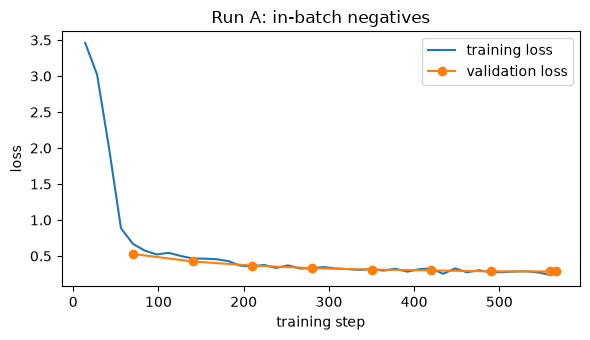

In [18]:
def plot_loss_curves(info, title):
    history = info["log_history"]
    train_points = [(h["step"], float(h["loss"])) for h in history if "loss" in h]
    eval_points = [(h["step"], float(h["eval_loss"])) for h in history if "eval_loss" in h]
    plt.figure(figsize=(6, 3.5))
    if train_points:
        plt.plot(*zip(*train_points), label="training loss")
    if eval_points:
        plt.plot(*zip(*eval_points), marker="o", label="validation loss")
    plt.xlabel("training step")
    plt.ylabel("loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_loss_curves(inbatch_info, "Run A: in-batch negatives")

## Part 7 — Hard negatives and fine-tuning, run B

**Random negatives are easy** ("a verse about war" vs. "a verse about food"). A **hard negative** is a wrong passage that *looks* right to the current model. Training against it should teach finer distinctions.

### How we mine them (for every training pair)
1. Embed all anchors and passages with the **base** model.
2. Look at the passages most similar to the anchor.
3. Skip the top 2 results and anything scoring above 95% of the true positive's score: those may be *correct answers nobody labelled* ("false negatives") and would teach the model the wrong thing.
4. Skip other views of the **same Gita verse** (another translation of the same verse is not a negative).
5. Pick randomly among the next 5 valid candidates.

Sanskrit and English passages are mined separately so that a hard negative is in the same language as the positive.

In [19]:
def mine_hard_negatives(rows, skip_top=2, sample_from=5, candidates=30, max_relative_score=0.95):
    """Returns the same rows with an added 'negative' field."""
    miner_rng = random.Random(RANDOM_SEED)
    model = SentenceTransformer(BASE_MODEL_NAME, device=DEVICE)
    model.max_seq_length = MAX_SEQ_LEN
    if DEVICE == "cuda":
        model.half()

    triplets, random_fallbacks = [], 0
    for positive_language in ("sanskrit", "english"):
        row_indices = [i for i, r in enumerate(rows) if r["positive_language"] == positive_language]

        passages, passage_verse_ids, passage_index = [], [], {}
        for i in row_indices:                      # unique passages of this language
            text = rows[i]["positive"]
            if text not in passage_index:
                passage_index[text] = len(passages)
                passages.append(text)
                passage_verse_ids.append(rows[i]["verse_id"])

        passage_vectors = torch.from_numpy(embed_texts(model, passages, "passage", BASE_MODEL_NAME, 128)).to(DEVICE)
        anchor_vectors = torch.from_numpy(embed_texts(
            model, [rows[i]["anchor"] for i in row_indices], "query", BASE_MODEL_NAME, 128)).to(DEVICE)
        if DEVICE == "cuda":
            passage_vectors, anchor_vectors = passage_vectors.half(), anchor_vectors.half()

        n_candidates = min(candidates, len(passages))
        for start in range(0, len(row_indices), 1024):
            chunk = row_indices[start:start + 1024]
            similarities = anchor_vectors[start:start + 1024] @ passage_vectors.T
            top_scores, top_ids = similarities.topk(n_candidates, dim=1)
            top_scores, top_ids = top_scores.float().cpu().numpy(), top_ids.cpu().numpy()

            for position, row_index in enumerate(chunk):
                row = rows[row_index]
                positive_id = passage_index[row["positive"]]
                positive_score = float(similarities[position, positive_id])
                valid = []
                for rank, (candidate_id, score) in enumerate(zip(top_ids[position], top_scores[position])):
                    if rank < skip_top or candidate_id == positive_id:
                        continue
                    same_gita_verse = row["verse_id"] != -1 and passage_verse_ids[candidate_id] == row["verse_id"]
                    if same_gita_verse or passages[candidate_id] == row["positive"]:
                        continue
                    if score > max_relative_score * positive_score:
                        continue
                    valid.append(int(candidate_id))
                    if len(valid) >= sample_from:
                        break
                if valid:
                    negative = passages[miner_rng.choice(valid)]
                else:                              # fall back to a random passage of the same language
                    random_fallbacks += 1
                    negative = passages[miner_rng.randrange(len(passages))]
                    while negative == row["positive"] and len(passages) > 1:
                        negative = passages[miner_rng.randrange(len(passages))]
                triplets.append({**row, "negative": negative})

    del model, passage_vectors, anchor_vectors
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    miner_rng.shuffle(triplets)
    print(f"mined {len(triplets)} triplets ({random_fallbacks} random fallbacks)")
    return triplets


triplet_rows = mine_hard_negatives(train_rows)
write_jsonl(triplet_rows, PROCESSED_DIR / "train_triplets.jsonl")

print("\nExamples (anchor / correct passage / mined hard negative):")
for row in [t for t in triplet_rows if t["source"] == "gita"][:3]:
    print("\n  ANCHOR  :", row["anchor"][:130])
    print("  POSITIVE:", row["positive"][:130])
    print("  NEGATIVE:", row["negative"][:130])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

mined 36285 triplets (36151 random fallbacks)

Examples (anchor / correct passage / mined hard negative):

  ANCHOR  : pūrvābhyāsena tenaiva hriyate hyavaśho ’pi saḥ jijñāsur api yogasya śhabda-brahmātivartate
  POSITIVE: पूर्वाभ्यासेन तेनैव ह्रियते ह्यवशोऽपि सः। जिज्ञासुरपि योगस्य शब्दब्रह्मातिवर्तते ॥
  NEGATIVE: गङ्गायाः सूतविषयं चप्पामनुययौ पुरीम्। स मञ्जूषागतो गर्भस्तरङ्गरुह्यमानकः॥

  ANCHOR  : Slay Drona, Bhisma, Jayadratha, and Karna, as well as the other heroes of the world—all already slain by Me. Do not be distressed;
  POSITIVE: द्रोणं च भीष्मं च जयद्रथं च कर्णं तथाऽन्यानपि योधवीरान्। मया हतांस्त्वं जहि मा व्यथिष्ठा युध्यस्व जेतासि रणे सपत्नान् ॥
  NEGATIVE: वधेन कर्णस्य तु दुःखितास्ते हा कर्ण हा कर्ण इति ब्रुवाणा। दुतं प्रयाताः शिबिराणि राजन् दिवाकरं रक्तमवेक्षमाणाः॥

  ANCHOR  : thus, according to the prescriptions of Vedic injunctions, therefore, sacrifice, performing, by uttering, expounders of the Vedas
  POSITIVE: तस्मादोमित्युदाहृत्य यज्ञदानतपःक्रियाः।प्रवर्तन्ते विध

model already exists, skipping training: d:\Sanskrit_Assignment2\Submission_Notebook\models\e5-ft-hardneg


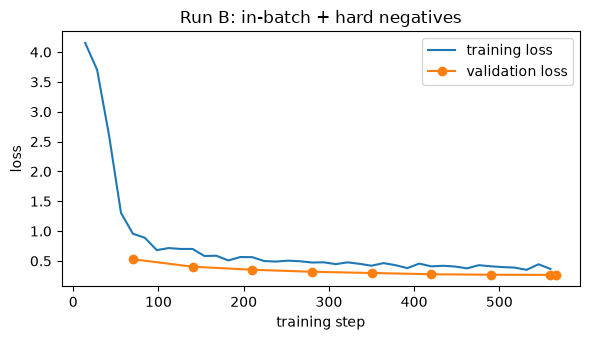

In [20]:
HARDNEG_DIR = MODELS_DIR / "e5-ft-hardneg"
if HARDNEG_DIR.exists() and not RETRAIN_IF_EXISTS:
    print("model already exists, skipping training:", HARDNEG_DIR)
    hardneg_info = read_json(HARDNEG_DIR / "train_info.json")
else:
    hardneg_info = train_model(triplet_rows, HARDNEG_DIR, include_hard_negative=True)
plot_loss_curves(hardneg_info, "Run B: in-batch + hard negatives")

## Part 8 — Final evaluation

Now all six systems are compared on all tasks, on the same held-out queries.

In [21]:
all_results["ft_inbatch"] = evaluate_system("ft_inbatch", str(INBATCH_DIR))
all_results["ft_hardneg"] = evaluate_system("ft_hardneg", str(HARDNEG_DIR))
SYSTEM_ORDER = ["bm25", "char_tfidf", "bge_small_en", "base_e5_small", "ft_inbatch", "ft_hardneg"]


def full_metrics_table(task_name):
    rows = []
    for system in SYSTEM_ORDER:
        m = all_results[system][task_name]["metrics"]
        rows.append({"system": system, "R@1": m["R@1"], "R@5": m["R@5"], "R@10": m["R@10"], "MRR@10": m["MRR@10"],
                     "MRR 95% CI": f"[{m['MRR@10_ci95'][0]:.3f}, {m['MRR@10_ci95'][1]:.3f}]", "nDCG@10": m["nDCG@10"]})
    return pd.DataFrame(rows).set_index("system")


markdown_lines = ["# Retrieval results", "",
                  "Queries come only from held-out verses. MRR@10 comes with a 95% bootstrap confidence interval.", ""]
for task_name, task in tasks.items():
    table = full_metrics_table(task_name)
    print(f"\n=== {task_name}: {task['description']}  ({len(task['queries'])} queries, corpus {len(task['corpus'])})")
    display(table.round(3))
    markdown_lines += [f"### {task_name}", "", f"{task['description']} ({len(task['queries'])} queries, "
                       f"corpus {len(task['corpus'])})", "", dataframe_to_markdown(table), ""]

summary_mrr = mrr_table({s: all_results[s] for s in SYSTEM_ORDER})
summary_mrr["mean"] = summary_mrr.mean(axis=1).round(3)
print("\n=== SUMMARY: MRR@10 (rows = systems, columns = tasks)")
display(summary_mrr)
markdown_lines += ["### Summary: MRR@10", "", dataframe_to_markdown(summary_mrr), ""]
(RESULTS_DIR / "metrics.md").write_text("\n".join(markdown_lines) + "\n", encoding="utf-8")
write_json({s: {t: r["metrics"] for t, r in all_results[s].items()} for s in SYSTEM_ORDER}, RESULTS_DIR / "metrics.json")
summary_mrr.to_csv(RESULTS_DIR / "summary_mrr.csv")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== T1_english_to_sanskrit: English paraphrase by an unseen translator (Shri Purohit Swami) -> Devanagari verse  (141 queries, corpus 701)


,R@1,R@5,R@10,MRR@10,MRR 95% CI,nDCG@10
system,,,,,,
bm25,0.000,0.000,0.014,0.002,"[0.000, 0.005]",0.005
char_tfidf,0.000,0.000,0.014,0.002,"[0.000, 0.005]",0.005
bge_small_en,0.000,0.007,0.014,0.003,"[0.000, 0.009]",0.006
base_e5_small,0.234,0.440,0.489,0.323,"[0.258, 0.385]",0.364
ft_inbatch,0.482,0.688,0.809,0.573,"[0.501, 0.643]",0.629
ft_hardneg,0.489,0.723,0.816,0.583,"[0.511, 0.651]",0.639



=== T2_sanskrit_to_english: Devanagari verse -> English translation (Swami Sivananda)  (141 queries, corpus 701)


...

,R@1,R@5,R@10,MRR@10,MRR 95% CI,nDCG@10
system,,,,,,
bm25,0.000,0.000,0.028,0.009,"[0.000, 0.023]",0.012
char_tfidf,0.000,0.000,0.028,0.009,"[0.000, 0.023]",0.012
bge_small_en,0.000,0.011,0.011,0.011,"[0.000, 0.033]",0.008
base_e5_small,0.050,0.225,0.225,0.165,"[0.072, 0.269]",0.161
ft_inbatch,0.269,0.394,0.486,0.501,"[0.322, 0.669]",0.418
ft_hardneg,0.269,0.400,0.494,0.511,"[0.332, 0.678]",0.425



=== T5_itihasa_sanskrit_to_english: Held-out Itihasa shloka -> its English translation  (1000 queries, corpus 1000)


,R@1,R@5,R@10,MRR@10,MRR 95% CI,nDCG@10
system,,,,,,
bm25,0.001,0.005,0.010,0.003,"[0.001, 0.006]",0.005
char_tfidf,0.002,0.005,0.011,0.004,"[0.001, 0.007]",0.005
bge_small_en,0.001,0.005,0.011,0.003,"[0.001, 0.006]",0.005
base_e5_small,0.188,0.330,0.403,0.252,"[0.228, 0.278]",0.288
ft_inbatch,0.790,0.912,0.944,0.844,"[0.824, 0.864]",0.868
ft_hardneg,0.804,0.914,0.943,0.853,"[0.832, 0.873]",0.875



=== SUMMARY: MRR@10 (rows = systems, columns = tasks)


,T1_english_to_sanskrit,T2_sanskrit_to_english,T3a_dataset_romanization,T3b_plain_ascii,T4a_concept_to_english,T4b_concept_to_sanskrit,T5_itihasa_sanskrit_to_english,mean
bm25,0.002,0.002,0.914,1.000,0.862,0.009,0.003,0.399
char_tfidf,0.002,0.002,1.000,1.000,0.822,0.009,0.004,0.406
bge_small_en,0.003,0.003,0.008,0.009,0.810,0.011,0.003,0.121
base_e5_small,0.323,0.317,0.225,0.224,0.778,0.165,0.252,0.326
ft_inbatch,0.573,0.850,0.744,0.826,0.782,0.501,0.844,0.731
ft_hardneg,0.583,0.857,0.690,0.763,0.763,0.511,0.853,0.717


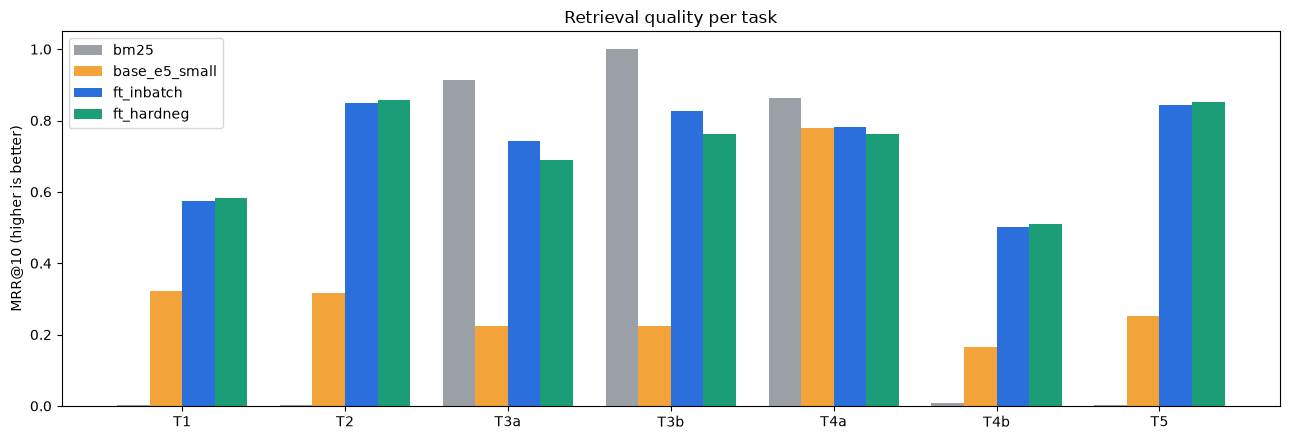

In [22]:
# One picture of the main comparison
plot_systems = ["bm25", "base_e5_small", "ft_inbatch", "ft_hardneg"]
colors = {"bm25": "#9aa0a6", "base_e5_small": "#f2a33a", "ft_inbatch": "#2a6fdb", "ft_hardneg": "#1b9e77"}
task_names = list(tasks)
width = 0.2
plt.figure(figsize=(13, 4.5))
for offset, system in enumerate(plot_systems):
    values = [all_results[system][t]["metrics"]["MRR@10"] for t in task_names]
    plt.bar(np.arange(len(task_names)) + offset * width, values, width, label=system, color=colors[system])
plt.xticks(np.arange(len(task_names)) + 1.5 * width, [t.split("_")[0] for t in task_names])
plt.ylabel("MRR@10 (higher is better)")
plt.title("Retrieval quality per task")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mrr_comparison.png", dpi=130)
plt.show()

## Part 9 — Error analysis and before/after examples

Averages hide *what* goes wrong. Here we look at individual queries.

### 9.1 Before vs after
The same concept question, answered by the base model (before) and by the fine-tuned model (after). A ✔ marks a correct verse.

In [23]:
def before_after_examples(task_name, before="base_e5_small", after="ft_inbatch", n=8):
    task = tasks[task_name]
    rows = []
    for q in range(min(n, len(task["queries"]))):
        query = task["queries"][q]
        row = {"query": query["text"][:95], "correct": ", ".join(query["relevant"])}
        for label, system in (("before", before), ("after", after)):
            top3 = [task["corpus"][d]["id"] for d in all_results[system][task_name]["ranked"][q][:3]]
            row[label] = ", ".join(f"{v}{'✔' if v in query['relevant'] else ''}" for v in top3)
        rows.append(row)
    return pd.DataFrame(rows)


examples = before_after_examples("T4b_concept_to_sanskrit")
display(examples)
(RESULTS_DIR / "before_after_examples.md").write_text(
    "# Before vs after (top-3 verses, tick = correct)\n\n" + dataframe_to_markdown(examples.set_index("query")), encoding="utf-8")

,query,correct,before,after
0,What does the Gita say about karma and acting without attachment to the results?,"2.47, 2.48, 3.19, 4.20","18.23, 18.13, 16.23","18.23, 18.11, 18.7"
1,Is the soul eternal? Is it ever born or does it die?,"2.19, 2.20, 2.23, 2.24","2.26, 13.33, 13.32","2.20✔, 2.26, 2.27"
2,"How does the soul take a new body after death, like changing clothes?","2.13, 2.22","13.33, 2.22✔, 15.8","2.22✔, 13.33, 3.33"
3,Why does God incarnate whenever righteousness declines?,"4.7, 4.8","16.8, 13.29, 12.2","16.8, 2.28, 8.1"
4,Abandon all duties and take refuge in me alone,"18.66, 18.65, 9.34","18.57, 12.6, 8.7","12.6, 3.30, 18.57"
5,What are the marks of a person of steady wisdom (sthitaprajna)?,"2.54, 2.55, 2.56","18.50, 12.3, 18.30","13.18, 13.6, 17.11"
6,Withdrawing the senses from their objects like a tortoise draws in its limbs,2.58,"18.38, 12.3, 18.33","3.34, 4.26, 5.9"
7,"How does dwelling on sense objects lead to desire, anger, delusion and ruin?","2.62, 2.63","18.53, 13.35, 7.4","2.63✔, 13.7, 6.21"


1119

### 9.2 Where does the fine-tuned model still fail?
For every query where the correct verse was **not ranked first**, we keep the query, the correct verse and what was returned instead (saved to `results/failures_ft_inbatch.jsonl`).

In [24]:
def collect_failures(system):
    failures = []
    for task_name, result in all_results[system].items():
        task = tasks[task_name]
        text_of_id = {d["id"]: d["text"] for d in task["corpus"]}
        for q, query in enumerate(task["queries"]):
            rank = result["first_hit_ranks"][q]
            if rank == 1:
                continue
            top = result["ranked"][q][:3]
            failures.append({
                "task": task_name, "query": query["text"][:260], "correct_ids": query["relevant"],
                "rank_of_first_correct": rank if rank else ">10",
                "correct_text": text_of_id[query["relevant"][0]][:260],
                "top1_id": task["corpus"][top[0]]["id"], "top1_text": task["corpus"][top[0]]["text"][:260],
            })
    return failures


failures = collect_failures("ft_inbatch")
write_jsonl(failures, RESULTS_DIR / "failures_ft_inbatch.jsonl")
failures_per_task = pd.DataFrame({
    "queries": {t: len(tasks[t]["queries"]) for t in tasks},
    "not ranked first": Counter(f["task"] for f in failures),
}).fillna(0).astype(int)
failures_per_task["% not first"] = (100 * failures_per_task["not ranked first"] / failures_per_task["queries"]).round(1)
display(failures_per_task)

print("\nSome failures of the fine-tuned model on cross-lingual tasks:")
shown = 0
for f in failures:
    if f["task"] in ("T4b_concept_to_sanskrit", "T1_english_to_sanskrit") and shown < 5:
        print(f"\n[{f['task']}] correct rank: {f['rank_of_first_correct']}")
        print("  QUERY  :", f["query"][:150])
        print(f"  CORRECT ({', '.join(f['correct_ids'][:3])}):", f["correct_text"][:110])
        print(f"  TOP-1   ({f['top1_id']}):", f["top1_text"][:110])
        shown += 1

,queries,not ranked first,% not first
T1_english_to_sanskrit,141,73,51.8
T2_sanskrit_to_english,141,30,21.3
T3a_dataset_romanization,141,47,33.3
T3b_plain_ascii,141,33,23.4
T4a_concept_to_english,30,8,26.7
T4b_concept_to_sanskrit,30,17,56.7
T5_itihasa_sanskrit_to_english,1000,210,21.0



Some failures of the fine-tuned model on cross-lingual tasks:

[T1_english_to_sanskrit] correct rank: >10
  QUERY  : Then, seated in their spacious war chariot, yoked with white horses, Lord Shri Krishna and Arjuna sounded their divine conch shells.
  CORRECT (1.14): ततः श्वेतैर्हयैर्युक्ते महति स्यन्दने स्थितौ। माधवः पाण्डवश्चैव दिव्यौ शङ्खौ प्रदध्मतुः ॥
  TOP-1   (1.21): अर्जुन उवाच हृषीकेशं तदा वाक्यमिदमाह महीपते। सेनयोरुभयोर्मध्ये रथं स्थापय मेऽच्युत ॥

[T1_english_to_sanskrit] correct rank: 2
  QUERY  : Where Bheeshma and Drona had led all the rulers of the earth, they spoke thus: O Arjuna! Behold, these members of the family of Kuru are assembled.
  CORRECT (1.25): भीष्मद्रोणप्रमुखतः सर्वेषां च महीक्षिताम्। उवाच पार्थ पश्यैतान्समवेतान्कुरूनिति ॥
  TOP-1   (2.4): अर्जुन उवाच कथं भीष्ममहं संख्ये द्रोणं च मधुसूदन। इषुभिः प्रतियोत्स्यामि पूजार्हावरिसूदन ॥

[T1_english_to_sanskrit] correct rank: >10
  QUERY  : And his heart melted with pity, and sadly he spoke: "O my Lord! When I see

In [25]:
# Rough failure categories for the verse-matching tasks (T1-T3), where every query has exactly one correct verse id
def categorize(failures_list):
    counts = Counter()
    for f in failures_list:
        if not f["task"].startswith(("T1", "T2", "T3")):
            continue
        correct_chapter, correct_verse = map(int, f["correct_ids"][0].split("."))
        top_chapter, top_verse = map(int, f["top1_id"].split("."))
        counts["correct verse in top 10 but not first" if f["rank_of_first_correct"] != ">10"
               else "correct verse not in top 10"] += 1
        if top_chapter == correct_chapter and abs(top_verse - correct_verse) <= 2:
            counts["top result is a neighbouring verse (within 2)"] += 1
        elif top_chapter == correct_chapter:
            counts["top result is from the same chapter"] += 1
    return counts


display(pd.Series(categorize(failures), name="count").to_frame())

,count
correct verse not in top 10,54
top result is from the same chapter,22
correct verse in top 10 but not first,129
top result is a neighbouring verse (within 2),10


**Typical failure patterns** (see `REPORT.md` for a longer discussion):

* **Concept ↔ Sanskrit vocabulary gap.** "Acting without attachment to results" should return verse 2.47 (*karmaṇy evādhikāras te…*), but the model returns *related* verses about unattached action. It understands the topic, not the exact verse.
* **Neighbouring verses.** Adjacent verses share names and themes and are easily confused.
* **Free paraphrase.** The held-out translator's wording drops names and key words the model relied on.
* **Plain-ASCII Sanskrit.** Without diacritics, long/short vowel distinctions are lost.

## Part 10 — What changed inside the embedding space?

Using the held-out verses, we compare the Sanskrit verse with an English paraphrase of the same verse (a *matching pair*) and with a random English paraphrase (a *random pair*).

* **Cosine similarity** 1.0 = same direction, 0 = unrelated.
* **Gap** = mean(matching) − mean(random). A bigger gap makes retrieval easier.
* If *random* pairs already have a high similarity, all vectors sit in a narrow cone ("anisotropy") and nothing stands out.
* A **PCA** picture shows whether Sanskrit and English form two separate clouds (the language dominates) or are mixed (the meaning dominates).

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,before: base e5-small,after: fine-tuned (run A)
"mean cosine, matching pairs",0.864,0.497
"mean cosine, random pairs",0.829,0.155
gap,0.035,0.342


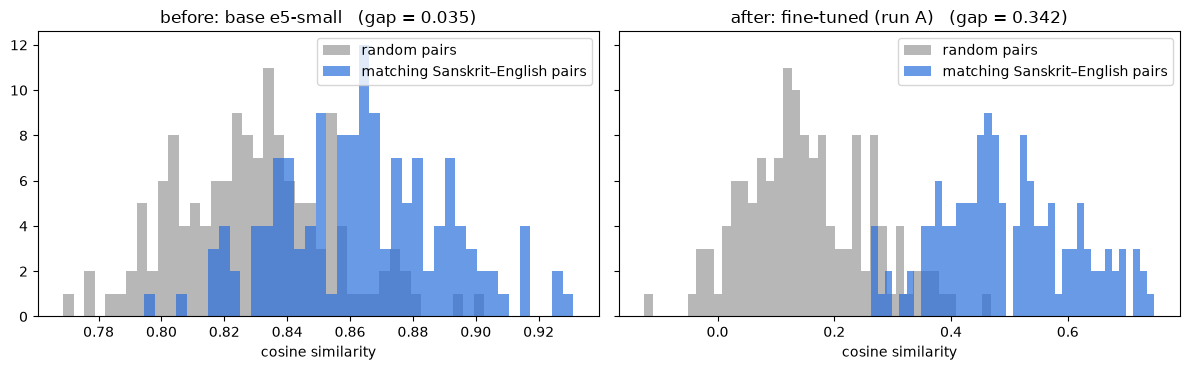

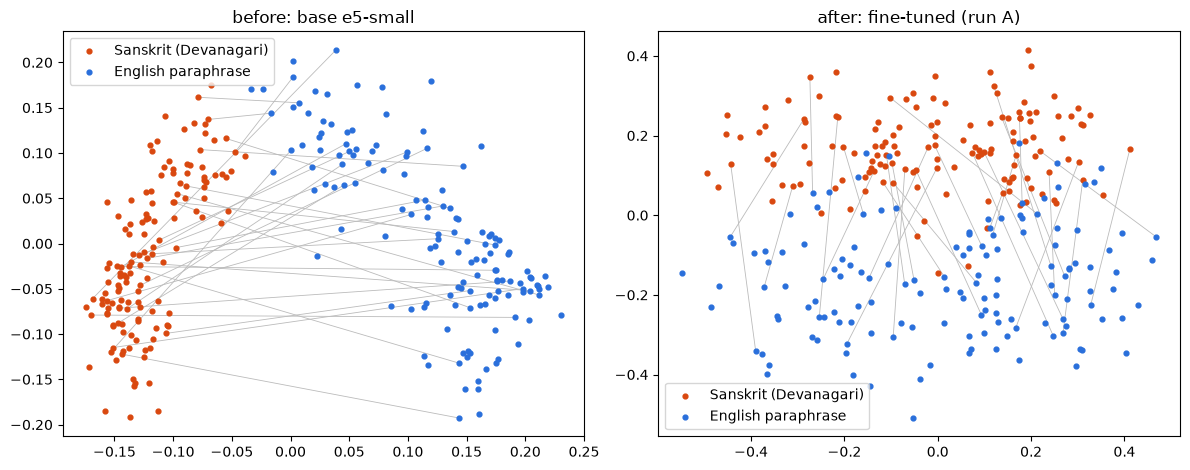

In [26]:
from sklearn.decomposition import PCA

test_verses = [v for v in verses if v["split"] == "test" and HELD_OUT_QUERY_AUTHOR in v["english_by_author"]]
sanskrit_texts = [v["sanskrit"] for v in test_verses]
english_texts = [v["english_by_author"][HELD_OUT_QUERY_AUTHOR] for v in test_verses]


def analyse_embeddings(model_path):
    model = SentenceTransformer(model_path, device=DEVICE)
    model.max_seq_length = 256
    sanskrit_vectors = embed_texts(model, sanskrit_texts, "passage", model_path)
    english_vectors = embed_texts(model, english_texts, "query", model_path)
    del model
    matching = (sanskrit_vectors * english_vectors).sum(axis=1)
    permutation = np.random.default_rng(0).permutation(len(english_vectors))
    permutation = np.where(permutation == np.arange(len(permutation)), (permutation + 1) % len(permutation), permutation)
    random_pairs = (sanskrit_vectors * english_vectors[permutation]).sum(axis=1)
    return {"matching": matching, "random": random_pairs, "S": sanskrit_vectors, "E": english_vectors,
            "mean_matching": float(matching.mean()), "mean_random": float(random_pairs.mean()),
            "gap": float(matching.mean() - random_pairs.mean())}


embedding_analysis = {
    "before: base e5-small": analyse_embeddings(BASE_MODEL_NAME),
    "after: fine-tuned (run A)": analyse_embeddings(str(INBATCH_DIR)),
}
display(pd.DataFrame({label: {"mean cosine, matching pairs": a["mean_matching"],
                              "mean cosine, random pairs": a["mean_random"], "gap": a["gap"]}
                      for label, a in embedding_analysis.items()}).round(3))

figure, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for axis, (label, a) in zip(axes, embedding_analysis.items()):
    axis.hist(a["random"], bins=40, alpha=0.6, color="#888888", label="random pairs")
    axis.hist(a["matching"], bins=40, alpha=0.7, color="#2a6fdb", label="matching Sanskrit–English pairs")
    axis.set_title(f"{label}   (gap = {a['gap']:.3f})")
    axis.set_xlabel("cosine similarity")
    axis.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "similarity_histograms.png", dpi=130)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, (label, a) in zip(axes, embedding_analysis.items()):
    points = PCA(n_components=2, random_state=0).fit_transform(np.concatenate([a["S"], a["E"]]))
    n = len(a["S"])
    for i in range(0, n, max(1, n // 25)):
        axis.plot([points[i, 0], points[n + i, 0]], [points[i, 1], points[n + i, 1]], color="#bbbbbb", lw=0.6, zorder=1)
    axis.scatter(points[:n, 0], points[:n, 1], s=12, color="#d9480f", label="Sanskrit (Devanagari)", zorder=2)
    axis.scatter(points[n:, 0], points[n:, 1], s=12, color="#2a6fdb", label="English paraphrase", zorder=2)
    axis.set_title(label)
    axis.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_languages.png", dpi=130)
plt.show()

**Reading the pictures**

* *Before:* matching and random pairs overlap almost completely and all similarities are about 0.8 (anisotropy). Sanskrit and English sit in **two separate clouds**.
* *After:* random pairs drop to ≈ 0.16 and matching pairs sit around 0.5, so the gap is about ten times larger, and the two languages are **mixed**: meaning, not language, now decides where a text goes.
* The absolute similarity of a true pair went *down* (0.86 → 0.5). That is healthy: the space is now spread out and discriminative, instead of everything being "similar".

## Part 11 — A small RAG demo

**RAG** (retrieval-augmented generation) = *first retrieve* the relevant passages, *then* let a language model answer using only those passages.

1. Every verse is one passage: Devanagari + English translation. (One shloka is a natural unit of ~35 tokens, so no further chunking is needed.)
2. The question is embedded with our fine-tuned model and the closest verses are returned.
3. *(Optional)* A small instruction-tuned LLM writes a short answer that must use only the retrieved verses and cite them.

In [31]:
# Build the search index once: embed every verse (Devanagari + English).
rag_model_path = str(INBATCH_DIR)
rag_model = SentenceTransformer(rag_model_path, device=DEVICE)
rag_model.max_seq_length = 256
rag_passages = [v["sanskrit"] + " — " + v["english_by_author"].get(ENGLISH_CORPUS_AUTHOR, "") for v in verses]
rag_vectors = embed_texts(rag_model, rag_passages, "passage", rag_model_path)
print("indexed", len(rag_passages), "verses; vector size", rag_vectors.shape[1])


def search(question, top_k=3):
    query_vector = embed_texts(rag_model, [question], "query", rag_model_path)[0]
    similarities = rag_vectors @ query_vector
    return [(verses[i], float(similarities[i])) for i in np.argsort(-similarities)[:top_k]]


def show_results(question, top_k=3):
    print("=" * 100, f"\nQUESTION: {question}")
    for verse, score in search(question, top_k):
        print(f"\n  [BG {verse['verse_ref']}]  similarity {score:.3f}")
        print("  ", verse["sanskrit"])
        print("  ", verse["romanized_iast"][:150])
        print("   EN:", verse["english_by_author"].get(ENGLISH_CORPUS_AUTHOR, "")[:260])


for question in ["How to meditate?",           # English question
                 "कर्मण्येवाधिकारस्ते",                              # a Sanskrit fragment
                 "dharmakshetre kurukshetre",                      # romanised Sanskrit
                 "How can the restless mind be controlled?"]:      # a concept question
    show_results(question)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indexed 701 verses; vector size 384
QUESTION: How to meditate?

  [BG 2.66]  similarity 0.373
   नास्ति बुद्धिरयुक्तस्य न चायुक्तस्य भावना। न चाभावयतः शान्तिरशान्तस्य कुतः सुखम् ॥
   nāsti buddhirayuktasya na cāyuktasya bhāvanā| na cābhāvayataḥ śāntiraśāntasya kutaḥ sukham ||
   EN: There is no knowledge of the Self for the unsteady, and no meditation is possible for the unsteady, and no peace for the unmeditative, and how can there be happiness for one who has no peace?

  [BG 10.17]  similarity 0.357
   कथं विद्यामहं योगिंस्त्वां सदा परिचिन्तयन्। केषु केषु च भावेषु चिन्त्योऽसि भगवन्मया ॥
   kathaṃ vidyāmahaṃ yogiṃstvāṃ sadā paricintayan| keṣu keṣu ca bhāveṣu cintyo'si bhagavanmayā ||
   EN: How shall I, ever meditating, know you, O Yogin? In what aspects or things, O blessed Lord, should I think of you?

  [BG 8.1]  similarity 0.339
   अर्जुन उवाच किं तद्ब्रह्म किमध्यात्मं किं कर्म पुरुषोत्तम। अधिभूतं च किं प्रोक्तमधिदैवं किमुच्यते ॥
   arjuna uvāca kiṃ tadbrahma kimadhyātmaṃ kiṃ kar

In [28]:
def generate_answer(question, top_k=3):
    """Small LLM answers using ONLY the retrieved verses, and must cite them."""
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
    llm = AutoModelForCausalLM.from_pretrained(
        LLM_NAME, dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
        device_map="auto" if DEVICE == "cuda" else None)
    hits = search(question, top_k)
    context = "\n\n".join(f"[BG {v['verse_ref']}] {v['sanskrit']}\nTranslation: "
                          f"{v['english_by_author'].get(ENGLISH_CORPUS_AUTHOR, '')}" for v, _ in hits)
    messages = [
        {"role": "system", "content": "You answer questions about the Bhagavad Gita using ONLY the verses provided. "
                                      "Write a short answer of 2-3 full sentences in plain English, then cite the verses "
                                      "you used as [BG chapter.verse]. If the verses do not answer the question, say so."},
        {"role": "user", "content": f"Verses:\n{context}\n\nQuestion: {question}"}]
    prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    encoded = tokenizer(prompt, return_tensors="pt").to(llm.device)
    output = llm.generate(**encoded, max_new_tokens=200, do_sample=False)
    answer = tokenizer.decode(output[0][encoded["input_ids"].shape[1]:], skip_special_tokens=True)
    del llm
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return hits, answer


rag_log = []
if RUN_LLM_ANSWER:
    for question in ["What does the Gita say about acting without attachment to the results?",
                     "Why does God incarnate whenever righteousness declines?"]:
        try:
            hits, answer = generate_answer(question)
            print(f"QUESTION: {question}\n  retrieved: {[v['verse_ref'] for v, _ in hits]}\n  ANSWER: {answer}\n")
            rag_log.append({"question": question, "retrieved": [v["verse_ref"] for v, _ in hits], "answer": answer})
        except Exception as error:     # the LLM is optional; the retrieval demo above already worked
            print("LLM answer skipped:", repr(error)[:200])
            break
    write_json(rag_log, RESULTS_DIR / "rag_llm_answers.json")
else:
    print("RUN_LLM_ANSWER is False: skipping the LLM answer.")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

QUESTION: What does the Gita say about acting without attachment to the results?
  retrieved: ['18.23', '18.7', '18.9']
  ANSWER: The Gita states that an action that is ordained, free from attachment, done without love or hatred, and without desire for reward is declared to be Sattvic.



Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

QUESTION: Why does God incarnate whenever righteousness declines?
  retrieved: ['4.7', '11.37', '6.37']
  ANSWER: Whenever there is a decline of righteousness and an increase of unrighteousness, O Arjuna, then I manifest Myself.



## Part 12 — Summary and honest limitations

### What we did
1. Built a leakage-aware dataset: held-out verses, a held-out translator, and Itihasa lines that quote the Gita removed.
2. Inspected tokenizers and chose **not** to extend the vocabulary (0% unknown tokens, too little Sanskrit text).
3. Fine-tuned `multilingual-e5-small` with contrastive learning, with and without mined hard negatives.
4. Evaluated against four baselines with Recall@K, MRR, nDCG and confidence intervals.
5. Analysed failures and the embedding space, and built a small RAG demo.

### Main findings (from the reference run; the tables above show *your* run)
* **Fine-tuning roughly doubles cross-lingual retrieval quality**, well outside the confidence intervals (MRR@10: English→Sanskrit 0.32 → 0.57, Sanskrit→English 0.32 → 0.85, question→Sanskrit 0.17 → 0.50, Itihasa 0.25 → 0.84).
* **Hard negatives did not help** here: run A and run B are statistically indistinguishable (B is behind on the romanised tasks), and run A is about 25% cheaper.
* **Keyword search beats embeddings on romanised queries.** If you know the romanisation scheme, convert the query to Devanagari (or romanise the corpus) instead of relying on embeddings. *The T3 benchmark is partly circular* because the baseline uses the same transliteration tool that produced the queries.
* **No gain on same-language English questions (T4a)**, where keyword search is best. We did not test general English benchmarks, so forgetting is not ruled out.

### Limitations
* One training run and one seed; only 141 (T1–T3) and 30 (T4) test queries, so small differences are noise.
* The 30 hand-written questions were written by one person after reading one translation, and their relevance labels are incomplete.
* Itihasa (T5) test verses come from the same distribution as the Itihasa training data, so T5 shows in-distribution learning, not out-of-domain generalisation.
* The RAG answer comes from a 0.5B LLM and was only spot-checked; retrieval errors propagate into the answer.

### What to improve with more time
Add Sanskrit–English glossaries and commentaries, LLM-generated synthetic questions per verse, hybrid retrieval (BM25 + dense), a cross-encoder re-ranker, several seeds, a LoRA vs full fine-tuning comparison and a general-English regression test.

**Files produced:** `results/` (tables, plots, failures, answers), `models/` (fine-tuned models), `data/processed/` (training pairs, evaluation tasks).

In [29]:
# Final bookkeeping: store what hardware / settings produced these results.
write_json({
    "quick_mode": QUICK_MODE, "device": GPU_NAME, "gpu_memory_gb": round(GPU_MEMORY_GB, 1),
    "base_model": BASE_MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_seq_len": MAX_SEQ_LEN,
    "learning_rate": LEARNING_RATE, "training_rows": len(train_rows),
    "run_a_minutes": inbatch_info.get("train_minutes"), "run_b_minutes": hardneg_info.get("train_minutes"),
    "peak_gpu_memory_gb": inbatch_info.get("peak_gpu_memory_gb"),
}, RESULTS_DIR / "run_summary.json")
print("all done. See the results/ folder.")

all done. See the results/ folder.
